<a href="https://colab.research.google.com/github/Jerefilms/DEEP-LEARNING/blob/main/YOLOSAMUEL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[INFO] Dispositivo en ejecución: cpu
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


Using cache found in /root/.cache/torch/hub/ultralytics_yolov5_master


YOLOv5 🚀 2026-11-25 Python-3.13.18 torch-2.14.1+cpu CPU



100%|██████████| 14.1M/14.1M [00:00<00:00, 105MB/s] 

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 
[INFO] Modelo YOLOv5s cargado exitosamente.
[INFO] Total de clases disponibles en COCO: 80

Prueba 1 - Escena Urbana con Múltiples Objetos | Umbral de confianza (conf): 0.25
image 1/1: 1080x810 4 persons, 1 bus
Speed: 516.3ms pre-process, 225.7ms inference, 34.0ms NMS per image at shape (1, 3, 640, 480)

Detalle de objetos detectados:
  name  confidence    xmin    ymin    xmax    ymax
person       0.882 672.297 393.932 810.000 875.516
person       0.866 220.436 406.629 345.908 869.927
   bus       0.855  15.032 220.635 799.227 796.771
person       0.842  49.077 391.319 248.703 912.550
person       0.494   0.114 552.532  68.449 877.591
[INFO] Evidencia guardada en: evidencias_yolov5/prueba1_umbral_025.jpg


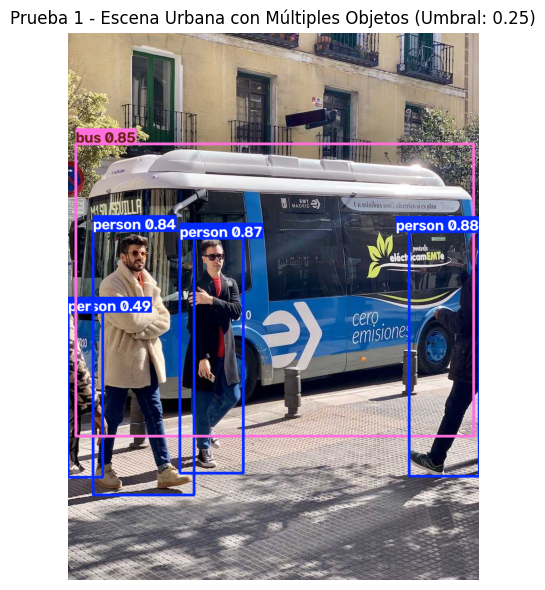


Prueba 2 - Segunda Escena (Distinta Composición y Escala) | Umbral de confianza (conf): 0.25
image 1/1: 720x1280 2 persons, 1 tie, 1 cell phone
Speed: 419.6ms pre-process, 188.3ms inference, 1.3ms NMS per image at shape (1, 3, 384, 640)

Detalle de objetos detectados:
      name  confidence    xmin    ymin     xmax    ymax
    person       0.869 745.579  48.470 1142.694 720.000
    person       0.630 124.744 197.335  844.397 716.651
       tie       0.617 441.239 439.351  498.381 708.571
cell phone       0.274 594.082 377.300  635.424 437.148
[INFO] Evidencia guardada en: evidencias_yolov5/prueba2_umbral_025.jpg


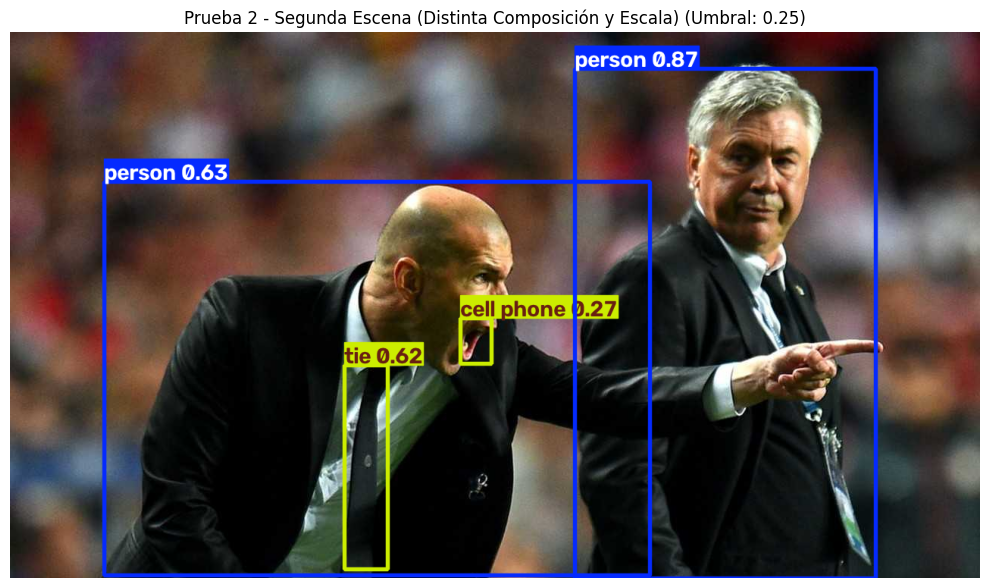


Comparación - Umbral Bajo (0.25) | Umbral de confianza (conf): 0.25
image 1/1: 1080x810 4 persons, 1 bus
Speed: 349.1ms pre-process, 220.8ms inference, 1.4ms NMS per image at shape (1, 3, 640, 480)

Detalle de objetos detectados:
  name  confidence    xmin    ymin    xmax    ymax
person       0.882 672.297 393.932 810.000 875.516
person       0.866 220.436 406.629 345.908 869.927
   bus       0.855  15.032 220.635 799.227 796.771
person       0.842  49.077 391.319 248.703 912.550
person       0.494   0.114 552.532  68.449 877.591
[INFO] Evidencia guardada en: evidencias_yolov5/comparacion_conf_025.jpg


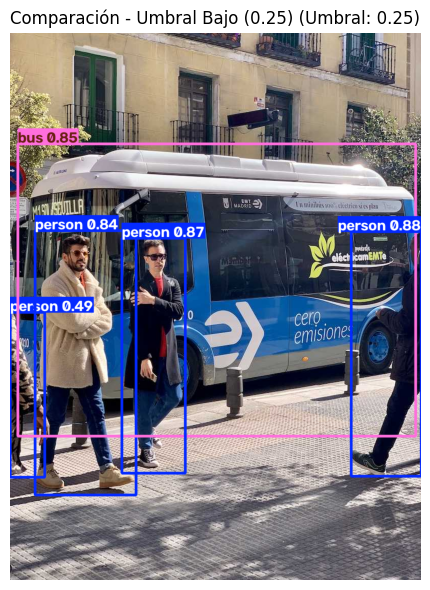


Comparación - Umbral Estándar/Alto (0.50) | Umbral de confianza (conf): 0.5
image 1/1: 1080x810 3 persons, 1 bus
Speed: 441.3ms pre-process, 233.1ms inference, 1.8ms NMS per image at shape (1, 3, 640, 480)

Detalle de objetos detectados:
  name  confidence    xmin    ymin    xmax    ymax
person       0.882 672.297 393.932 810.000 875.516
person       0.866 220.436 406.629 345.908 869.927
   bus       0.855  15.032 220.635 799.227 796.771
person       0.842  49.077 391.319 248.703 912.550
[INFO] Evidencia guardada en: evidencias_yolov5/comparacion_conf_050.jpg


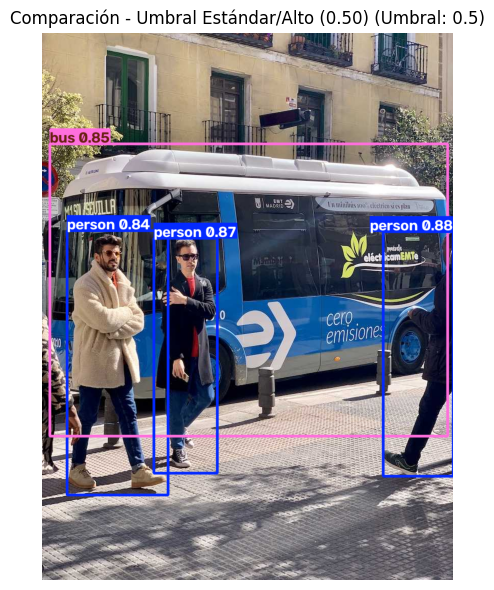


TABLA COMPARATIVA DE CONTEOS SEGÚN UMBRAL
        Confianza >= 0.25  Confianza >= 0.50
name                                        
person                  4                  3
bus                     1                  1


In [2]:
# ACTIVIDAD R2-A3-S12: IMPLEMENTACIÓN Y ANÁLISIS DE YOLOv5 PREENTRENADO SAMUEL DAVID CELIS

# Instalar dependencias necesarias para YOLOv5
!pip install -q ultralytics

#PREPARACIÓN DEL ENTORNO Y CARGA DEL MODELO YOLOv5

import os
import torch
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

# Verificar disponibilidad de GPU o CPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"[INFO] Dispositivo en ejecución: {device}")

# Cargar modelo YOLOv5s preentrenado
model = torch.hub.load("ultralytics/yolov5", "yolov5s", pretrained=True, trust_repo=True)
model.to(device)
model.eval()

print("[INFO] Modelo YOLOv5s cargado exitosamente.")
print(f"[INFO] Total de clases disponibles en COCO: {len(model.names)}")

# Carpeta para guardar todas las evidencias visuales y reportes
os.makedirs("evidencias_yolov5", exist_ok=True)



# FUNCIÓN AUXILIAR PARA EJECUTAR DETECCIÓN, MOSTRAR Y GUARDAR RESULTADOS

def ejecutar_deteccion(ruta_o_url_imagen, umbral_conf=0.25, titulo="Detección YOLOv5", nombre_archivo="salida.jpg"):
    """
    Ejecuta YOLOv5 sobre una imagen (ruta local o URL) con un umbral de confianza dado,
    imprime el resumen de objetos detectados, muestra la imagen anotada y la guarda.
    """
    model.conf = umbral_conf  # Configurar umbral de confianza
    results = model(ruta_o_url_imagen)

    # Imprimir resumen en consola
    print("\n" + "=" * 70)
    print(f"{titulo} | Umbral de confianza (conf): {umbral_conf}")
    print("=" * 70)
    results.print()

    # Extraer tabla estructurada de detecciones (xmin, ymin, xmax, ymax, confidence, class, name)
    df_det = results.pandas().xyxy[0]
    if not df_det.empty:
        print("\nDetalle de objetos detectados:")
        print(df_det[["name", "confidence", "xmin", "ymin", "xmax", "ymax"]].round(3).to_string(index=False))
    else:
        print("\nNo se detectaron objetos por encima del umbral configurado.")

    # Renderizar imagen con bounding boxes y etiquetas
    img_renderizada = results.render()[0]  # Arreglo NumPy RGB

    # Guardar imagen anotada en disco para descargar y adjuntar al informe PDF
    ruta_guardado = os.path.join("evidencias_yolov5", nombre_archivo)
    Image.fromarray(img_renderizada).save(ruta_guardado)
    print(f"[INFO] Evidencia guardada en: {ruta_guardado}")

    # Visualizar en Colab
    plt.figure(figsize=(10, 6))
    plt.imshow(img_renderizada)
    plt.axis("off")
    plt.title(f"{titulo} (Umbral: {umbral_conf})")
    plt.tight_layout()
    plt.show()

    return results, df_det



# PRIMERA PRUEBA DE DETECCIÓN (ESCENA CON MÚLTIPLES OBJETOS)


imagen_prueba_1 = "https://ultralytics.com/images/bus.jpg"

res_1, df_1 = ejecutar_deteccion(
    ruta_o_url_imagen=imagen_prueba_1,
    umbral_conf=0.25,
    titulo="Prueba 1 - Escena Urbana con Múltiples Objetos",
    nombre_archivo="prueba1_umbral_025.jpg"
)



#SEGUNDA PRUEBA DE DETECCIÓN (CONDICIONES DISTINTAS DE COMPLEJIDAD/TAMAÑO)


imagen_prueba_2 = "https://ultralytics.com/images/zidane.jpg"

res_2, df_2 = ejecutar_deteccion(
    ruta_o_url_imagen=imagen_prueba_2,
    umbral_conf=0.25,
    titulo="Prueba 2 - Segunda Escena (Distinta Composición y Escala)",
    nombre_archivo="prueba2_umbral_025.jpg"
)



# PASO 4: COMPARACIÓN DE RESULTADOS CON UMBRALES 0.25 Y 0.50

# Elegimos la Imagen 1 (o cambia a `imagen_prueba_2` si prefieres comparar la segunda)
imagen_comparacion = imagen_prueba_1

_, df_conf_025 = ejecutar_deteccion(
    ruta_o_url_imagen=imagen_comparacion,
    umbral_conf=0.25,
    titulo="Comparación - Umbral Bajo (0.25)",
    nombre_archivo="comparacion_conf_025.jpg"
)

_, df_conf_050 = ejecutar_deteccion(
    ruta_o_url_imagen=imagen_comparacion,
    umbral_conf=0.50,
    titulo="Comparación - Umbral Estándar/Alto (0.50)",
    nombre_archivo="comparacion_conf_050.jpg"
)

# Tabla comparativa cuantitativa entre umbral 0.25 y 0.50
conteo_025 = df_conf_025["name"].value_counts().rename("Confianza >= 0.25")
conteo_050 = df_conf_050["name"].value_counts().rename("Confianza >= 0.50")

tabla_comparativa = pd.concat([conteo_025, conteo_050], axis=1).fillna(0).astype(int)
print("\n" + "=" * 70)
print("TABLA COMPARATIVA DE CONTEOS SEGÚN UMBRAL")
print("=" * 70)
print(tabla_comparativa)